<a href="https://colab.research.google.com/github/elbuh0/genai-course/blob/main/genai-course/week4/Week_4_Lab4_SDXL_ControlNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 4 — Text-to-Image & Latent Space Exploration
**COM SCI-X 455 · Week 4 · Megan Armani, PhD**

> Push to `genai-course/week4/`  |  GPU: T4 or A10G required

---

## Setup

In [ ]:
!pip install diffusers transformers accelerate xformers torch --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 3.2 MB/s eta 0:00:00


In [ ]:
import torch
from diffusers import (StableDiffusionXLPipeline, DPMSolverMultistepScheduler,
                        StableDiffusionXLControlNetPipeline, ControlNetModel,
                        DDIMScheduler)
from PIL import Image
import numpy as np, matplotlib.pyplot as plt, time

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)
print("VRAM:", torch.cuda.get_device_properties(0).total_memory/1e9, "GB" if DEVICE=='cuda' else "N/A")

    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.11.0+cu130)
    Python  3.10.19 (you have 3.13.15)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details


Device: cuda
VRAM: 15.637086208 GB


## Part 1 — SDXL Pipeline + CFG Sweep

In [ ]:
pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16, use_safetensors=True
).to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
print("SDXL loaded")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

SDXL loaded


  0%|          | 0/30 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


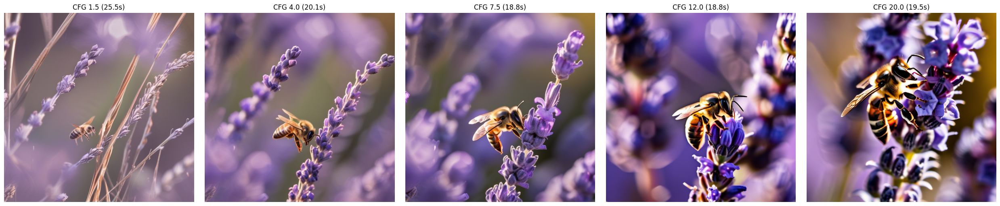

In [ ]:
# TODO: Run the same prompt at CFG scales: [1.5, 4.0, 7.5, 12.0, 20.0]
# Use the same seed (torch.Generator('cuda').manual_seed(42)) for each.
# Prompt: 'a photorealistic macro photograph of a honeybee on lavender, golden hour'
# Display all 5 in a 1x5 grid. Label each with its CFG value.
# Note: at what CFG does quality peak? When does it degrade?

# Experiment 1: CFG Scale Sweep

import time
import torch
import matplotlib.pyplot as plt

prompt = "a photorealistic macro photograph of a honeybee on lavender, golden hour"
negative = "blurry, low quality, cartoon, illustration, oversaturated, watermark"

results = {}
for cfg in [1.5, 4.0, 7.5, 12.0, 20.0]:
    t0 = time.time()
    img = pipe(
        prompt=prompt,
        negative_prompt=negative,
        guidance_scale=cfg,
        num_inference_steps=30,
        height=768, width=768,
        generator=torch.Generator("cuda").manual_seed(42),
    ).images[0]
    results[cfg] = {"image": img, "time": time.time() - t0}
    img.save(f"cfg_{cfg}.png")

# 1x5 grid
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for ax, (cfg, r) in zip(axes, results.items()):
    ax.imshow(r["image"])
    ax.set_title(f"CFG {cfg} ({r['time']:.1f}s)")
    ax.axis("off")
plt.tight_layout()
plt.show()

  0%|          | 0/20 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


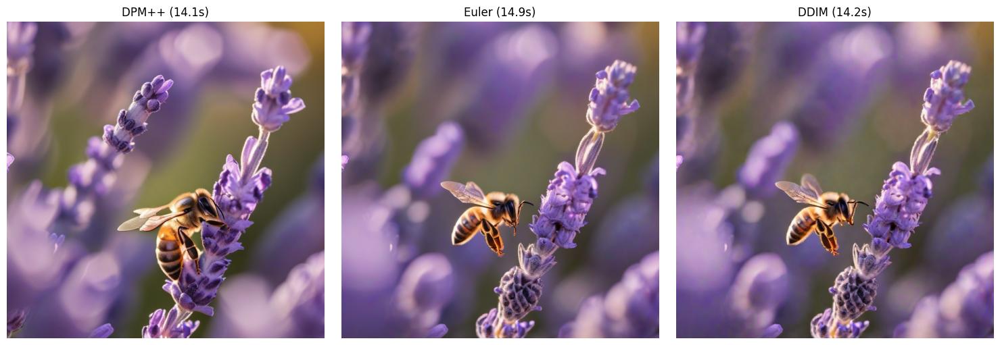

In [ ]:
# Experiment 2: Scheduler Comparison
import time
from diffusers import DPMSolverMultistepScheduler, EulerDiscreteScheduler, DDIMScheduler

base_config = pipe.scheduler.config          # save original once

schedulers = {
    "DPM++": DPMSolverMultistepScheduler,
    "Euler": EulerDiscreteScheduler,
    "DDIM": DDIMScheduler,
}

sched_results = {}
for name, SchedClass in schedulers.items():
    pipe.scheduler = SchedClass.from_config(base_config)
    t0 = time.time()
    img = pipe(
        prompt=prompt,
        negative_prompt=negative,
        guidance_scale=7.5,
        num_inference_steps=20,
        height=768, width=768,
        generator=torch.Generator("cuda").manual_seed(42),
    ).images[0]
    sched_results[name] = {"image": img, "time": time.time() - t0}
    img.save(f"sched_{name}.png")

pipe.scheduler = DPMSolverMultistepScheduler.from_config(base_config)  # restore default

# 1x3 grid
fig, axes = plt.subplots(1, len(sched_results), figsize=(15, 5))
for ax, (name, r) in zip(axes, sched_results.items()):
    ax.imshow(r["image"])
    ax.set_title(f"{name} ({r['time']:.1f}s)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Part 2 — ControlNet Conditioning

In [ ]:
from google.colab import files

uploaded = files.upload()                 # opens a file picker
ref_image = next(iter(uploaded))          # filename of what you uploaded
print("Using:", ref_image)


Saving IMG_1770.JPG to IMG_1770 (1).JPG
Using: IMG_1770 (1).JPG


In [1]:
# Canny Edge ControlNet
import cv2, numpy as np, torch, time
from PIL import Image
import matplotlib.pyplot as plt
from diffusers import StableDiffusionXLControlNetPipeline, ControlNetModel

controlnet = ControlNetModel.from_pretrained(
    "diffusers/controlnet-canny-sdxl-1.0", torch_dtype=torch.float16
)

DEVICE = "cuda"
pipe_cn = StableDiffusionXLControlNetPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    controlnet=controlnet,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True,
).to(DEVICE)

def get_canny(image_path, size=768, low=100, high=200):
    img = Image.open(image_path).convert("RGB").resize((size, size))
    edges = cv2.Canny(np.array(img), low, high)
    return Image.fromarray(np.stack([edges] * 3, axis=-1))

canny_map = get_canny(ref_image)

prompt = ("1969 Mustang coupe in dark ocean teal with black racing stripes, "
          "freshly detailed, mean and muscular, golden hour")
negative = "blurry, low quality"

cn_results = {}
for scale in [0.0, 0.5, 1.0]:              # 0.0 = unconditioned baseline
    t0 = time.time()
    img = pipe_cn(
        prompt=prompt,
        negative_prompt=negative,
        image=canny_map,
        controlnet_conditioning_scale=scale,
        guidance_scale=7.5,
        num_inference_steps=30,
        height=768, width=768,
        generator=torch.Generator("cuda").manual_seed(42),
    ).images[0]
    cn_results[scale] = {"image": img, "time": time.time() - t0}
    img.save(f"controlnet_scale_{scale}.png")

# Edge map + 3 results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (scale, r) in zip(axes, cn_results.items()):
    ax.imshow(r["image"])
    ax.set_title(f"scale {scale} ({r['time']:.1f}s)")
    ax.axis("off")
plt.tight_layout(); plt.show()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 5.00GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


...

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

NameError: name 'ref_image' is not defined

### 🎯 GitHub Portfolio Callout
Your 1x3 ControlNet comparison = your README header image.
Save it: `fig.savefig('controlnet_comparison.png', dpi=150, bbox_inches='tight')`

## Part 3 — Latent Space Interpolation via DDIM Inversion

In [2]:
import torch
DEVICE = "cuda"
from diffusers import StableDiffusionXLPipeline

pipe_ddim = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16, variant="fp16", use_safetensors=True,
).to(DEVICE)
print(f"{torch.cuda.memory_allocated()/1e9:.1f} GB in use")   # expect ~7

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

7.1 GB in use


The config attributes {'interpolation_type': 'linear', 'use_karras_sigmas': False, 'skip_prk_steps': True} were passed to DDIMInverseScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.


Saving fileA.JPG to fileA (4).JPG
Saving fileB.jpg to fileB (4).jpg
fileA (4).JPG | fileB (4).jpg


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/50 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


...

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/50 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/50 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


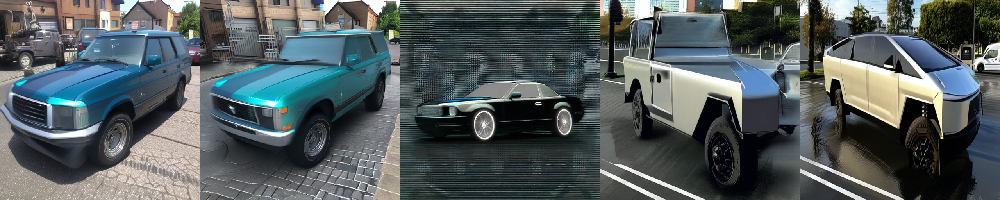

In [6]:
pathA, pathB = "fileA.jpg", "fileB.jpg"

import torch
from PIL import Image

from google.colab import files
up = files.upload()            # pick both images at once
pathA, pathB = list(up)[:2]
print(pathA, "|", pathB)

import torch
from diffusers import DDIMScheduler, DDIMInverseScheduler

# pipe_ddim already loaded in the setup cell
pipe_ddim.scheduler = DDIMScheduler.from_config(pipe_ddim.scheduler.config)
inv_sched = DDIMInverseScheduler.from_config(pipe_ddim.scheduler.config)

prompt = ""
imageA = Image.open(pathA).convert("RGB").resize((768, 768))
imageB = Image.open(pathB).convert("RGB").resize((768, 768))

@torch.no_grad()
def ddim_invert(pipe, image, n_steps=50):
  """Encode an image back to its latent representation (approximate)"""
  # Encode image to latent
  pipe.vae.to(torch.float32)
  image_tensor = pipe.image_processor.preprocess(image).to("cuda", dtype=torch.float32)
  latent = pipe.vae.encode(image_tensor).latent_dist.mean
  latent = (latent * pipe.vae.config.scaling_factor).half()
  pipe.vae.to(torch.float16)
  # SDXL text + extra conditioning
  text_emb, _, pooled, _ = pipe.encode_prompt(prompt, device="cuda",
      num_images_per_prompt=1, do_classifier_free_guidance=False)
  cond = {"text_embeds": pooled,
          "time_ids": torch.tensor([[768, 768, 0, 0, 768, 768]], device="cuda", dtype=text_emb.dtype)}
  # Run inversion (forward DDIM) to get the noise that generated this image
  inv_sched.set_timesteps(n_steps, device="cuda")
  for t in inv_sched.timesteps:
    noise_pred = pipe.unet(latent, t,
      encoder_hidden_states=text_emb, added_cond_kwargs=cond).sample   # CHANGED
    latent = inv_sched.step(noise_pred, t, latent).prev_sample     # CHANGED
  return latent

# Invert two images to get z_A and z_B
z_A = ddim_invert(pipe_ddim, imageA)
z_B = ddim_invert(pipe_ddim, imageB)

# Interpolate between them
interpolations = []
for t in [0.0, 0.25, .5, .75, 1.0]:
  # z_t = (1-t)*z_A + t*z_B          # original lerp; swap to slerp(z_A, z_B, t) for full-strength middles
  z_t = ((1-t)*z_A + t*z_B) / ((1-t)**2 + t**2) ** 0.5
  # Decode z_t back to image via DDIM sampling from this starting point
  img = pipe_ddim(latents=z_t, prompt="a car", num_inference_steps=50,
                guidance_scale=5.0, height=768, width=768).images[0]
  interpolations.append(img)

# Create 1x5 interpolation grid
grid = Image.new("RGB", (5*512, 512))
for i, img in enumerate(interpolations):
  grid.paste(img.resize((512, 512)), (i*512, 0))
grid.save("latent_interpolation.png")
grid

The config attributes {'interpolation_type': 'linear', 'use_karras_sigmas': False, 'skip_prk_steps': True} were passed to DDIMInverseScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Saving fileB.jpg to fileB (5).jpg
Saving fileC.jpg to fileC.jpg
fileB (5).jpg | fileC.jpg


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/50 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


...

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/50 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/50 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


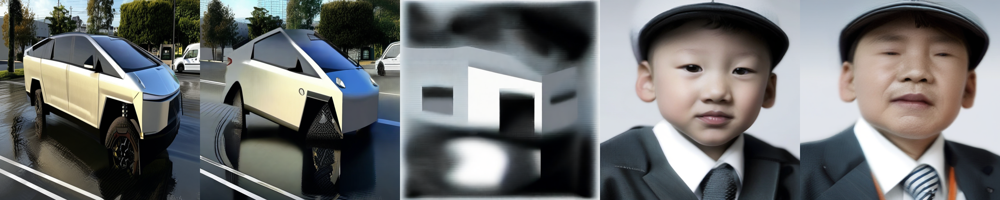

In [7]:
# TODO: Generate 2 images with different seeds (seed=0 and seed=99), same prompt.
pathA, pathB = "fileA.jpg", "fileB.jpg"

import torch
from PIL import Image

from google.colab import files
up = files.upload()            # pick both images at once
pathA, pathB = list(up)[:2]
print(pathA, "|", pathB)

import torch
from diffusers import DDIMScheduler, DDIMInverseScheduler

# pipe_ddim already loaded in the setup cell
pipe_ddim.scheduler = DDIMScheduler.from_config(pipe_ddim.scheduler.config)
inv_sched = DDIMInverseScheduler.from_config(pipe_ddim.scheduler.config)

prompt = ""
imageA = Image.open(pathA).convert("RGB").resize((768, 768))
imageB = Image.open(pathB).convert("RGB").resize((768, 768))

@torch.no_grad()
def ddim_invert(pipe, image, n_steps=50):
  """Encode an image back to its latent representation (approximate)"""
  # Encode image to latent
  pipe.vae.to(torch.float32)
  image_tensor = pipe.image_processor.preprocess(image).to("cuda", dtype=torch.float32)
  latent = pipe.vae.encode(image_tensor).latent_dist.mean
  latent = (latent * pipe.vae.config.scaling_factor).half()
  pipe.vae.to(torch.float16)
  # SDXL text + extra conditioning
  text_emb, _, pooled, _ = pipe.encode_prompt(prompt, device="cuda",
      num_images_per_prompt=1, do_classifier_free_guidance=False)
  cond = {"text_embeds": pooled,
          "time_ids": torch.tensor([[768, 768, 0, 0, 768, 768]], device="cuda", dtype=text_emb.dtype)}
  # Run inversion (forward DDIM) to get the noise that generated this image
  inv_sched.set_timesteps(n_steps, device="cuda")
  for t in inv_sched.timesteps:
    noise_pred = pipe.unet(latent, t,
      encoder_hidden_states=text_emb, added_cond_kwargs=cond).sample   # CHANGED
    latent = inv_sched.step(noise_pred, t, latent).prev_sample     # CHANGED
  return latent

# Invert two images to get z_A and z_B
z_A = ddim_invert(pipe_ddim, imageA)
z_B = ddim_invert(pipe_ddim, imageB)

# Interpolate between them
interpolations = []
for t in [0.0, 0.25, .5, .75, 1.0]:
  # z_t = (1-t)*z_A + t*z_B          # original lerp; swap to slerp(z_A, z_B, t) for full-strength middles
  z_t = ((1-t)*z_A + t*z_B) / ((1-t)**2 + t**2) ** 0.5
  # Decode z_t back to image via DDIM sampling from this starting point
  img = pipe_ddim(latents=z_t, prompt="a car", num_inference_steps=50,
                guidance_scale=5.0, height=768, width=768).images[0]
  interpolations.append(img)

# Create 1x5 interpolation grid
grid = Image.new("RGB", (5*512, 512))
for i, img in enumerate(interpolations):
  grid.paste(img.resize((512, 512)), (i*512, 0))
grid.save("latent_interpolation.png")
grid

# Deployment Decision

1. You ran SDXL at CFG 1.5, 4.0, 7.5, 12.0, and 20. Describe in technical terms what changed at each level. At what point did quality improve, plateau, and degrade? Reference the guidance scale formula to explain mechanistically why CFG > 15 causes saturation and artifacts?

Technically, CFG attempts to balance photorealism with prompt adherence, or the (1) probability of photo-realistic output (p(x)); scaled by (2) the degree to which the output matches the user prompt (p(c|x)); raised by (3) a user-defined value determining strength of prompt adherence called CFG scale (g), i.e., p(x) * p(c|x)^g.

At CFG 1.5, i.e. p(x) * p(c|x)^1.5, images that more closely adhere to user prompt are more strongly favored, albeit only weakly so when compared to higher CFG values of 4, 7.5, 12, and 20. At 1.5, prompt guidance such as lighting ("golden hour"), colors ("lavender"), and fine details (e.g. bee anatomical structures) may be only coarsely rendered. This setting however allows for greater sampling diversity (at the expense of prompt adherence).

At CFG 4, i.e., p(x) · p(c|x)^4, prompt adherence is clearly stronger than at 1.5: composition is coherent and prompt elements (golden-hour lighting, lavender, bee anatomy) are rendered well, if slightly soft. Because p(x) still carries substantial weight, contrast and saturation remain natural and the output stays close to the model's distribution of realistic photographs.

At CFG 7.5, i.e., p(x) · p(c|x)^7.5, prompt adherence is much stronger and sitting at a recommended "sweet spot" between photo-realism and prompt-adherence. Fine details such as bee and floral anatomy are rendered precisely, along with colors and lighting. As p(x) is not yet entirely diluted, the output remains close to the model's distribution of realistic photographs. Quality has improved.

At CFG 12 to 20, i.e., p(x) · p(c|x)^12 and p(x) · p(c|x)^20, prompt adherence now takes precedence over photorealism, e.g., a bee with cartoonishly bug-like eyes, and lavender of a hue so stark it would never appear in nature. The model is pushed to the exaggerated extremes of the prompt-match term, beyond its training distribution, collapsing photorealism, collapsing photorealism. Quality clearly degrades.

2. Your ControlNet comparison showed that conditioning scale = 1.0 constrained creativity compared to scale=.5. A product manager said just use 1.0 so the outputs look consistent. Write a 3 sentence techncial response explaining the tradeoff and recommending a specific scale for a product catalogue use case.

ControlNet's conditioning scale multiplies the residuals added to the skip connections at every corresponding resolution as the image is denoised. At .5, they are weak, so the output may stray from the initial edge map more than at 1, i.e. full-strength, which locks in the structure -even if errant, due to a poor control image- from the get-go. We can certainly use 1.0; however, don't expect much in the way of creativity in shape and composition, and errors inherent to any bad control images will alo propagate through subsequent outputs.

3. Your latent interpolation between two dissimilar images produced incoherent midpoints. Explain why this happens in the latent space geometry, and describe one technique that would produce more coherent interpolation between dissimilar images.

Latent interpolation between two dissimilar images produced incoherent midpoints because there is no realistic midpoint between the reference images of a Tesla Cybertruck and Nicolas Cage, as the model was accordingly never trained on such a non-existent entity -there is an empty wasteland in the model's internal representation between FaceLand and Car Island. You could add semantic anchors like "car" and "face" to force an intermediary output of say vehicle headlights and a grill arranged in such a manner as to vaguely recall the outline of a face.

4. A startup asks you to chose between open-weight SDXL, DALL-E 3 API and Midjourney (Discord) for three use cases: a. branded product photography for new ecommerce site; b. concept art for internal ideation; c. synthetic medical imaging for a research project. Recommend one tool per use case with full reasoning.

For branded product photography for a new ecommerce site, I would recommend SDXL given strong consistency but also ensuring branded imagery, i.e. potential IP, remains internal. Regarding concept art for internal ideation, I would suggest Midjourney, given ease of use, as well as great default aesthetics and parameters; stealth mode can also be enabled to keep what would be better kept internal, internal (albeit at an extra cost). As for synthetic medical imaging, I would boil down my recommendation rationale to simply confidentiality, which means only a locally hosted open-weight SDXL fine-tuned on medical images (with clinician validation and checks against memorizing real patient data) will do of the three.

---
## Submission
- [ ] Push to `genai-course/week4/lab4.ipynb`
- [ ] CFG sweep grid saved
- [ ] ControlNet comparison saved as `controlnet_comparison.png`
- [ ] Latent interpolation grid shown
- [ ] README updated with best images

## Part 4 — CLIP Score Evaluation
**Goal:** Compute CLIP score to measure text-image alignment. Required for Homework Part 3.

In [ ]:
!pip install open-clip-torch --quiet
import open_clip, torch
from PIL import Image

clip_model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
tokenizer = open_clip.get_tokenizer('ViT-B-32')
clip_model.eval()

def clip_score(image: Image.Image, prompt: str) -> float:
    """Compute cosine similarity between image and text prompt using CLIP."""
    img_tensor  = preprocess(image).unsqueeze(0)
    text_tensor = tokenizer([prompt])
    with torch.no_grad():
        img_feat  = clip_model.encode_image(img_tensor)
        txt_feat  = clip_model.encode_text(text_tensor)
        img_feat /= img_feat.norm(dim=-1, keepdim=True)
        txt_feat /= txt_feat.norm(dim=-1, keepdim=True)
    return (img_feat @ txt_feat.T).item()

print("CLIP scorer ready")

In [ ]:
# TODO: Run clip_score() on your images from Parts 1-3.
For each image, compute: clip_score(image, original_prompt)
Build a table: Part | Prompt (first 50 chars) | CLIP Score | Notes

Questions to answer:
- Does higher CFG correlate with higher CLIP score?
- Does ControlNet conditioning improve or hurt CLIP score?
- Which of your 5 generated images has the highest CLIP score?
